# Credit Card Fraud Detection: Modeling, Evaluation and Business Recommendation

**Notebook 2 of 2.** Notebook 1 (`1_eda_and_baseline.ipynb`) covered data cleaning, EDA, feature engineering and a Logistic Regression baseline. This notebook builds on it to answer the research question:

> *Can a machine learning model flag fraudulent credit card transactions accurately enough to catch most fraud while keeping false alarms on legitimate customers low, and which approach gives the best balance of fraud losses prevented versus customers wrongly inconvenienced?*

### What this notebook does
1. Trains and tunes **five supervised models** with **GridSearchCV** and **time-aware cross-validation**: Logistic Regression with three different ways of handling the imbalance (class weighting, SMOTE, undersampling), Random Forest and XGBoost.
2. Tests **two unsupervised anomaly detectors** (Isolation Forest, One-Class SVM) that never see fraud labels.
3. Compares all seven models on a held-out test set and **interprets the best one**.
4. Turns the best model into a **business decision**: which alert threshold minimizes the combined cost of missed fraud and alert reviews, and how that compares with having no model or using a simple rule.

As in notebook 1, each step explains **why** I'm doing it, and each result is followed by **what I found** in plain language.

**Run time:** about 15 minutes on a typical laptop; the Random Forest grid search is the slowest step.

## 1. Setup

**Why this step:** all libraries are imported up front. Two are new compared with notebook 1: **imbalanced-learn**, which provides SMOTE and undersampling inside a pipeline so resampling only ever touches training data, and **XGBoost**, a gradient-boosting library that is a strong performer on tabular data like this.

In [1]:
# --- Core data libraries ---
import time
import numpy as np
import pandas as pd

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- scikit-learn: preprocessing, models, validation, metrics ---
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score, f1_score,
    precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
)

# --- Imbalance handling (imbalanced-learn) and gradient boosting (XGBoost) ---
from imblearn.pipeline import Pipeline as ImbPipeline   # pipeline that allows resampling steps
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

import os
import warnings
warnings.filterwarnings("ignore")   # keep output readable (library deprecation notices)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42          # fixed seed so results are reproducible
N_JOBS = -1                # use all CPU cores for the slower models
IMAGE_DIR = "../images"    # charts used in the README are saved here
os.makedirs(IMAGE_DIR, exist_ok=True)

## 2. Load and Prepare the Data

**Why this step:** this repeats the cleaning and feature engineering from notebook 1 in compact form, so this notebook can run on its own. The reasoning behind each step is explained in notebook 1.

**Currency note:** the source never states the currency of `Amount`. Since the cardholders were European, I show amounts with a € sign, but this is an assumption. It doesn't affect any model result.

In [2]:
# Load the raw Kaggle file (see README for download instructions)
df_raw = pd.read_csv("data/creditcard.csv")

# Cleaning (same as notebook 1): remove the 1,081 exact duplicate rows
df = df_raw.drop_duplicates().reset_index(drop=True)

# Feature engineering (same as notebook 1)
df["Hour"] = (df["Time"] // 3600) % 24                 # hour of day
df["IsNight"] = df["Hour"].between(1, 7).astype(int)   # low-volume, high-fraud-rate hours
df["LogAmount"] = np.log1p(df["Amount"])               # reduces skew in Amount
df["IsMicroAmount"] = (df["Amount"] <= 1).astype(int)  # card-testing signal

v_cols = [f"V{i}" for i in range(1, 29)]
feature_cols = v_cols + ["LogAmount", "Hour", "IsNight", "IsMicroAmount"]

print(f"Clean dataset: {len(df):,} transactions | {df['Class'].sum()} fraud ({df['Class'].mean():.3%})")
print(f"Features used for modeling: {len(feature_cols)}")

Clean dataset: 283,726 transactions | 473 fraud (0.167%)
Features used for modeling: 32


## 3. Time-Ordered Split and Time-Aware Cross-Validation

**Why this step:** a bank trains its fraud model on past transactions and uses it on future ones, so I evaluate the models the same way.

- **Final test set:** the latest 20% of transactions are locked away and used only once, at the very end, to report results.
- **Cross-validation:** to tune each model's settings fairly, I use `TimeSeriesSplit` on the training data. Ordinary k-fold cross-validation shuffles data, which would let the model learn from later transactions and be validated on earlier ones. `TimeSeriesSplit` always trains on an earlier block and validates on the block that comes right after it, as the chart below shows.

I use 3 folds so that each validation block still contains a reasonable number of frauds (57–106), which keeps the scores stable.

In [3]:
# Sort chronologically: train on the earliest 80%, hold back the latest 20% as the final test set.
# The test set is used ONCE, at the end, to report results. All tuning happens on the training set.
df_sorted = df.sort_values("Time").reset_index(drop=True)
split_idx = int(len(df_sorted) * 0.8)
train, test = df_sorted.iloc[:split_idx], df_sorted.iloc[split_idx:]

X_train, y_train = train[feature_cols], train["Class"]
X_test, y_test = test[feature_cols], test["Class"]
amount_test = test["Amount"].values     # kept aside for the business-cost analysis

# Time-aware cross-validation: each fold trains on earlier data and validates on the block
# that immediately follows, so the model is never validated on the past.
cv = TimeSeriesSplit(n_splits=3)

fold_rows = []
for i, (tr_idx, val_idx) in enumerate(cv.split(X_train), start=1):
    fold_rows.append({"Fold": i, "Train rows": len(tr_idx), "Validation rows": len(val_idx),
                      "Fraud in validation": int(y_train.iloc[val_idx].sum())})
fold_rows.append({"Fold": "Final test", "Train rows": len(train), "Validation rows": len(test),
                  "Fraud in validation": int(y_test.sum())})
pd.DataFrame(fold_rows).set_index("Fold")

,Train rows,Validation rows,Fraud in validation
Fold,,,
1,56745,56745,79
2,113490,56745,106
3,170235,56745,57
Final test,226980,56746,74


**What I found:** the training data splits into three validation blocks of about 56,700 transactions each, and each fold trains on everything before its block. The final test set has 74 frauds. The fraud count varies across blocks (57 to 106), a reminder that fraud levels shift over time, which is exactly why a time-aware evaluation is more realistic than a random one.

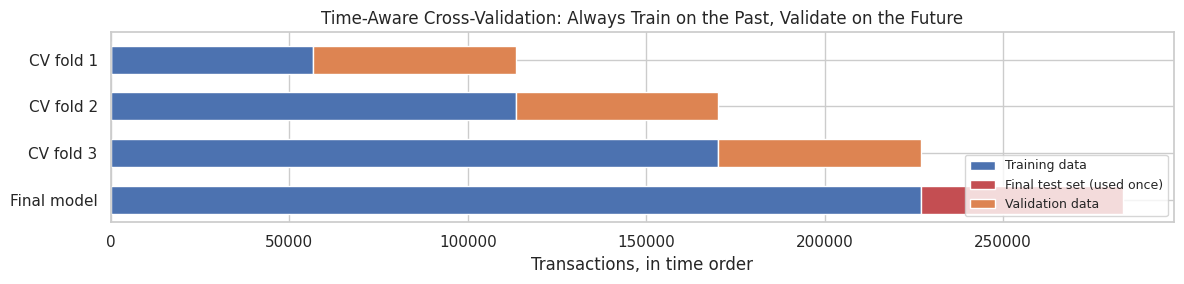

In [4]:
# Visualize the folds: blue = data used for training, orange = data used for validation/testing
fig, ax = plt.subplots(figsize=(12, 3))
n_train = len(X_train)
for i, (tr_idx, val_idx) in enumerate(cv.split(X_train)):
    ax.barh(i, len(tr_idx), left=0, color="#4C72B0", height=0.6)
    ax.barh(i, len(val_idx), left=tr_idx[-1] + 1, color="#DD8452", height=0.6)
ax.barh(3, n_train, left=0, color="#4C72B0", height=0.6, label="Training data")
ax.barh(3, len(test), left=n_train, color="#C44E52", height=0.6, label="Final test set (used once)")
ax.barh(0, 0, color="#DD8452", label="Validation data")
ax.set_yticks(range(4))
ax.set_yticklabels(["CV fold 1", "CV fold 2", "CV fold 3", "Final model"])
ax.invert_yaxis()
ax.set_xlabel("Transactions, in time order")
ax.set_title("Time-Aware Cross-Validation: Always Train on the Past, Validate on the Future")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**How to read the chart:** each row is one round of training. Blue is the data the model learns from, orange is the block it's validated on, and red is the final test set, which no model touches until Section 7. Notice that orange always sits to the right of blue: the model is never validated on the past.

## 4. Evaluation Metric and Helper Functions

**Evaluation metric: Precision-Recall AUC (PR-AUC).** Notebook 1 explains this choice in detail. In short:
- **Recall** = share of all fraud the model catches (missed fraud costs money).
- **Precision** = share of alerts that are real fraud (false alarms cost review time and annoy customers).
- **PR-AUC** summarizes the precision-recall trade-off across every possible alert threshold, focusing on the rare fraud class. Random guessing scores about 0.0013 on the test set, so it has a meaningful floor.
- **Accuracy is not used,** because a model that never flags fraud is 99.87% accurate. ROC-AUC is reported for reference, but it flatters weak models on imbalanced data; Section 7 shows a clear example.

All models are **selected on cross-validation PR-AUC**, not on test results, so the test set gives an honest estimate of real-world performance.

The helper functions below avoid repeating the same tuning and scoring code for every model.

In [5]:
def test_metrics(name, y_score, y_pred=None, train_seconds=np.nan):
    """Score a model's test-set fraud scores (and optional yes/no predictions)."""
    row = {
        "Model": name,
        "PR-AUC": average_precision_score(y_test, y_score),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    }
    if y_pred is not None:   # anomaly detectors have no natural 0.5 cut-off, so these are skipped
        row.update({
            "Precision @0.5": precision_score(y_test, y_pred, zero_division=0),
            "Recall @0.5": recall_score(y_test, y_pred),
            "F1 @0.5": f1_score(y_test, y_pred),
        })
    row["Train time (s)"] = train_seconds
    return row


def tune(name, estimator, param_grid):
    """Grid-search a model with time-aware CV, scored by PR-AUC, and report the results."""
    start = time.time()
    search = GridSearchCV(estimator, param_grid, cv=cv, scoring="average_precision",
                          n_jobs=N_JOBS, refit=True)
    search.fit(X_train, y_train)
    elapsed = time.time() - start

    # Compact table of every combination tried, best first
    cv_table = (pd.DataFrame(search.cv_results_)
                  .loc[:, ["params", "mean_test_score", "std_test_score"]]
                  .rename(columns={"mean_test_score": "CV PR-AUC (mean)", "std_test_score": "CV PR-AUC (std)"})
                  .sort_values("CV PR-AUC (mean)", ascending=False)
                  .round(3))
    print(f"{name} | best CV PR-AUC: {search.best_score_:.3f} | search time: {elapsed:.0f}s")
    print(f"Best parameters: {search.best_params_}")
    return search, elapsed, cv_table


# Collect everything for the comparison in Section 7
cv_scores, test_rows, test_scores, best_models = {}, [], {}, {}

def record(name, search, elapsed):
    """Store a tuned model's CV score, test scores and test metrics."""
    y_score = search.predict_proba(X_test)[:, 1]
    y_pred = search.predict(X_test)
    cv_scores[name] = search.best_score_
    test_scores[name] = y_score
    best_models[name] = search.best_estimator_
    test_rows.append(test_metrics(name, y_score, y_pred, elapsed))

## 5. Supervised Models, Tuned with GridSearchCV

**Why this step:** supervised models learn from labeled examples of fraud and legitimate transactions. For each one, `GridSearchCV` tries every combination of a few key settings (hyperparameters), scores each combination with time-aware cross-validation, and keeps the best.

I keep each grid small and focused on the settings that matter most, both because the dataset is large and because on this data the scores turn out to be fairly insensitive to fine-tuning (as the tables show).

The first three models are all Logistic Regression. Keeping the model fixed lets me compare **three strategies for handling the imbalance** on equal terms, as planned in my proposal.

### 5.1 Logistic Regression with class weighting

In [6]:
# Class weighting: missed fraud is penalized more heavily than a false alarm during training.
# C controls regularization strength (smaller C = simpler model, less overfitting).
lr_weighted = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
])
search_lr, t_lr, table_lr = tune("Logistic Regression (class weights)", lr_weighted,
                                 {"model__C": [0.01, 0.1, 1]})
record("Logistic Regression (class weights)", search_lr, t_lr)
table_lr

Logistic Regression (class weights) | best CV PR-AUC: 0.756 | search time: 9s
Best parameters: {'model__C': 0.1}


,params,CV PR-AUC (mean),CV PR-AUC (std)
1,{'model__C': 0.1},0.756,0.040
0,{'model__C': 0.01},0.753,0.035
2,{'model__C': 1},0.751,0.040


**What I found:** the best setting is C = 0.1 (moderate regularization), with a cross-validation PR-AUC of **0.756**, but all three values of C score within 0.005 of each other. The standard deviation across folds (about 0.04) is far larger than the differences between settings, so for Logistic Regression the choice of C barely matters on this data.

### 5.2 Logistic Regression with SMOTE oversampling

In [7]:
# SMOTE creates synthetic fraud examples by interpolating between real ones.
# Inside an imblearn pipeline it is applied ONLY to each training fold, never to validation data.
# sampling_strategy = desired fraud-to-legitimate ratio after oversampling.
lr_smote = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
search_smote, t_smote, table_smote = tune("Logistic Regression (SMOTE)", lr_smote,
                                          {"smote__sampling_strategy": [0.1, 0.5],
                                           "model__C": [0.01, 1]})
record("Logistic Regression (SMOTE)", search_smote, t_smote)
table_smote

Logistic Regression (SMOTE) | best CV PR-AUC: 0.753 | search time: 16s
Best parameters: {'model__C': 0.01, 'smote__sampling_strategy': 0.1}


,params,CV PR-AUC (mean),CV PR-AUC (std)
0,"{'model__C': 0.01, 'smote__sampling_strategy':...",0.753,0.046
1,"{'model__C': 0.01, 'smote__sampling_strategy':...",0.753,0.035
2,"{'model__C': 1, 'smote__sampling_strategy': 0.1}",0.749,0.044
3,"{'model__C': 1, 'smote__sampling_strategy': 0.5}",0.739,0.018


**What I found:** the best SMOTE setting oversamples fraud to 10% of the legitimate class, with strong regularization (C = 0.01), scoring **0.753**. Creating more synthetic fraud (50%) didn't help, and with weak regularization (C = 1) it made things slightly worse: with many synthetic points, the model starts fitting the artificial examples rather than real fraud patterns. Overall, SMOTE performs about the same as simple class weighting, while adding complexity and training time.

### 5.3 Logistic Regression with random undersampling

In [8]:
# Undersampling discards legitimate transactions until the desired ratio is reached.
# Again applied only to training folds.
lr_under = ImbPipeline([
    ("scaler", StandardScaler()),
    ("under", RandomUnderSampler(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
search_under, t_under, table_under = tune("Logistic Regression (undersampling)", lr_under,
                                          {"under__sampling_strategy": [0.01, 0.1, 1.0],
                                           "model__C": [0.01, 1]})
record("Logistic Regression (undersampling)", search_under, t_under)
table_under

Logistic Regression (undersampling) | best CV PR-AUC: 0.735 | search time: 7s
Best parameters: {'model__C': 0.01, 'under__sampling_strategy': 0.1}


,params,CV PR-AUC (mean),CV PR-AUC (std)
1,"{'model__C': 0.01, 'under__sampling_strategy':...",0.735,0.063
0,"{'model__C': 0.01, 'under__sampling_strategy':...",0.732,0.061
2,"{'model__C': 0.01, 'under__sampling_strategy':...",0.690,0.107
3,"{'model__C': 1, 'under__sampling_strategy': 0.01}",0.668,0.095
4,"{'model__C': 1, 'under__sampling_strategy': 0.1}",0.587,0.104
5,"{'model__C': 1, 'under__sampling_strategy': 1.0}",0.442,0.219


**What I found:** undersampling is the weakest of the three strategies (best **0.735**) and the most unstable. With a 1:1 ratio and weak regularization, the score collapses to 0.442. Balancing the classes 1:1 means keeping only about 400 legitimate transactions out of 226,000, which throws away almost all information about normal behavior. Mild undersampling (10%) with strong regularization works best, but still trails class weighting.

**Comparison of imbalance strategies (Logistic Regression, cross-validation PR-AUC):** class weighting **0.756** > SMOTE **0.753** > undersampling **0.735**. The simplest approach, telling the model that fraud matters more, is as good as or better than resampling the data. This matches the expectation in my proposal that the imbalance technique would matter less than the choice of model.

### 5.4 Random Forest

In [9]:
# Random Forest: many decision trees trained on random subsets of rows and features, then averaged.
# Trees don't need feature scaling. class_weight="balanced_subsample" re-weights fraud in each tree.
# max_depth limits how complex each tree can get; min_samples_leaf stops trees memorizing single cases.
# (This is the slowest search in the notebook: several minutes on a typical laptop.)
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            random_state=RANDOM_STATE, n_jobs=N_JOBS)
search_rf, t_rf, table_rf = tune("Random Forest", rf,
                                 {"max_depth": [8, None], "min_samples_leaf": [1, 5]})
record("Random Forest", search_rf, t_rf)
table_rf

Random Forest | best CV PR-AUC: 0.777 | search time: 574s
Best parameters: {'max_depth': 8, 'min_samples_leaf': 5}


,params,CV PR-AUC (mean),CV PR-AUC (std)
1,"{'max_depth': 8, 'min_samples_leaf': 5}",0.777,0.016
3,"{'max_depth': None, 'min_samples_leaf': 5}",0.776,0.010
2,"{'max_depth': None, 'min_samples_leaf': 1}",0.767,0.022
0,"{'max_depth': 8, 'min_samples_leaf': 1}",0.763,0.008


**What I found:** Random Forest reaches a cross-validation PR-AUC of **0.777**, clearly above every Logistic Regression variant. The best setting limits tree depth to 8 and requires at least 5 transactions per leaf. Requiring 5 per leaf helps in both depth settings, because it stops trees from memorizing individual fraud cases. The scores are also more stable across folds (std 0.016 vs 0.04 for Logistic Regression). The downside is training time: almost 10 minutes for this grid.

### 5.5 XGBoost (gradient boosting)

In [10]:
# XGBoost builds trees one after another, each correcting the errors of the previous ones.
# scale_pos_weight up-weights fraud (1 = no extra weight). learning_rate and max_depth control
# how quickly and how flexibly the model learns.
xgb = XGBClassifier(n_estimators=300, tree_method="hist", eval_metric="aucpr",
                    random_state=RANDOM_STATE, n_jobs=N_JOBS)
search_xgb, t_xgb, table_xgb = tune("XGBoost", xgb,
                                    {"max_depth": [3, 5], "learning_rate": [0.05, 0.1],
                                     "scale_pos_weight": [1, 10]})
record("XGBoost", search_xgb, t_xgb)
table_xgb

XGBoost | best CV PR-AUC: 0.778 | search time: 92s
Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'scale_pos_weight': 10}


,params,CV PR-AUC (mean),CV PR-AUC (std)
7,"{'learning_rate': 0.1, 'max_depth': 5, 'scale_...",0.778,0.007
3,"{'learning_rate': 0.05, 'max_depth': 5, 'scale...",0.777,0.004
0,"{'learning_rate': 0.05, 'max_depth': 3, 'scale...",0.777,0.005
2,"{'learning_rate': 0.05, 'max_depth': 5, 'scale...",0.776,0.003
5,"{'learning_rate': 0.1, 'max_depth': 3, 'scale_...",0.774,0.005
6,"{'learning_rate': 0.1, 'max_depth': 5, 'scale_...",0.774,0.004
4,"{'learning_rate': 0.1, 'max_depth': 3, 'scale_...",0.763,0.014
1,"{'learning_rate': 0.05, 'max_depth': 3, 'scale...",0.757,0.002


**What I found:** XGBoost has the best cross-validation PR-AUC of all models (**0.778**), with the lowest variation across folds (std 0.007). Its best setting uses depth-5 trees, a learning rate of 0.1, and a modest extra weight of 10 on fraud. The top six combinations all score between 0.774 and 0.778, so XGBoost performs well without delicate tuning, a good sign for a model that would need regular retraining.

## 6. Unsupervised Anomaly Detection

**Why this step:** supervised models can only learn fraud patterns that appear in their labeled training data. Fraudsters change tactics, and new fraud often has no label yet. Anomaly detectors don't use labels at all: they learn what "normal" looks like and score how unusual each transaction is. Notebook 1 found that statistically extreme transactions contain 86% of all fraud, so this approach looked promising.

Because these models don't use labels, there is no fair way to grid-search them without cheating (tuning on fraud labels would make them supervised). I use standard settings instead.

In [11]:
# Isolation Forest: no labels used. It isolates each transaction with random splits;
# unusual transactions are isolated in fewer splits and get a higher anomaly score.
start = time.time()
iso = IsolationForest(n_estimators=200, random_state=RANDOM_STATE, n_jobs=N_JOBS)
iso.fit(X_train)                                  # note: y_train is NOT used
t_iso = time.time() - start
iso_scores = -iso.decision_function(X_test)       # flip sign so higher = more anomalous

test_scores["Isolation Forest (unsupervised)"] = iso_scores
test_rows.append(test_metrics("Isolation Forest (unsupervised)", iso_scores, train_seconds=t_iso))
print(f"Isolation Forest test PR-AUC: {average_precision_score(y_test, iso_scores):.3f}")

Isolation Forest test PR-AUC: 0.044


**What I found:** Isolation Forest scores a test PR-AUC of only **0.044**. That is about 30 times better than random guessing, but far below the supervised models.

In [12]:
# One-Class SVM: learns a boundary around "typical" transactions. It scales poorly with data size,
# so it is trained on a random sample of 10,000 training transactions (again, without labels).
start = time.time()
ocsvm_scaler = StandardScaler().fit(X_train)
ocsvm_sample = X_train.sample(10_000, random_state=RANDOM_STATE)
ocsvm = OneClassSVM(nu=0.01, gamma="scale").fit(ocsvm_scaler.transform(ocsvm_sample))
t_ocsvm = time.time() - start
ocsvm_scores = -ocsvm.decision_function(ocsvm_scaler.transform(X_test))   # higher = more anomalous

test_scores["One-Class SVM (unsupervised)"] = ocsvm_scores
test_rows.append(test_metrics("One-Class SVM (unsupervised)", ocsvm_scores, train_seconds=t_ocsvm))
print(f"One-Class SVM test PR-AUC: {average_precision_score(y_test, ocsvm_scores):.3f}")

One-Class SVM test PR-AUC: 0.063


**What I found:** One-Class SVM does slightly better at **0.063**, but it is still a weak detector. Unusual is not the same as fraudulent: many legitimate transactions are also unusual (large purchases, rare merchants), and the anomaly detectors flag those too.

## 7. Model Comparison on the Test Set

**Why this step:** this is the first time any model sees the test set. Comparing all seven models side by side shows which approach works best, and whether the cross-validation scores were a reliable guide.

In [13]:
# One table with every model. CV PR-AUC is what the models were selected on;
# test PR-AUC is how they perform on the held-out final 20% of transactions.
comparison = pd.DataFrame(test_rows).set_index("Model")
comparison.insert(0, "CV PR-AUC", pd.Series(cv_scores))
comparison = comparison.sort_values("CV PR-AUC", ascending=False, na_position="last")
comparison.round(3)

,CV PR-AUC,PR-AUC,ROC-AUC,Precision @0.5,Recall @0.5,F1 @0.5,Train time (s)
Model,,,,,,,
XGBoost,0.778,0.802,0.987,0.902,0.743,0.815,91.842
Random Forest,0.777,0.802,0.987,0.814,0.770,0.792,574.104
Logistic Regression (class weights),0.756,0.769,0.986,0.028,0.932,0.054,9.343
Logistic Regression (SMOTE),0.753,0.759,0.985,0.337,0.811,0.476,15.633
Logistic Regression (undersampling),0.735,0.753,0.986,0.513,0.784,0.620,6.944
Isolation Forest (unsupervised),NaN,0.044,0.951,NaN,NaN,NaN,1.297
One-Class SVM (unsupervised),NaN,0.063,0.939,NaN,NaN,NaN,1.043


**What I found:**
- **Tree-based models win.** XGBoost and Random Forest both reach a test PR-AUC of **0.802**, ahead of the best Logistic Regression (0.769). Their advantage is that they can capture non-linear patterns and combinations of features.
- **Cross-validation was a reliable guide.** The ranking on the test set matches the cross-validation ranking, and test scores are close to (slightly above) the CV scores, so there is no sign of overfitting.
- **At the default 0.5 threshold, the models behave very differently.** XGBoost flags few transactions, and 90% of its alerts are real fraud (catching 74% of fraud). Class-weighted Logistic Regression catches 93% of fraud, but only 2.8% of its alerts are real. This shows again that the default threshold is not a sensible business setting; Section 9 addresses this.
- **ROC-AUC is misleading here.** The anomaly detectors score a respectable-looking ROC-AUC of about 0.94–0.95, yet their PR-AUC is below 0.07. ROC-AUC treats false alarms as a share of all 56,000 legitimate transactions, so even thousands of false alarms look small. This is exactly why I chose PR-AUC as the main metric.
- **Unsupervised models are not competitive** as standalone detectors on this data.

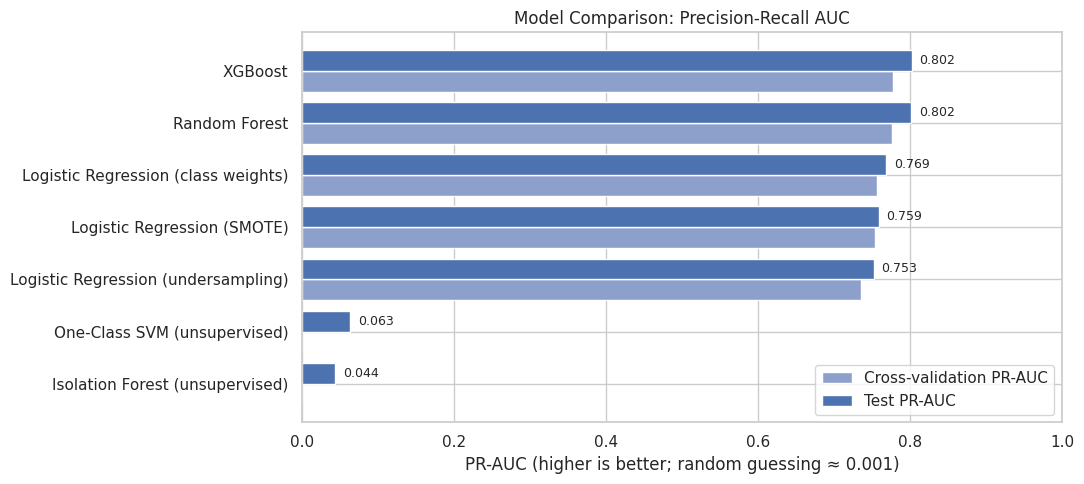

In [14]:
# Bar chart: CV vs test PR-AUC for each model
plot_df = comparison[["CV PR-AUC", "PR-AUC"]].rename(columns={"PR-AUC": "Test PR-AUC"})
plot_df = plot_df.sort_values("Test PR-AUC")

fig, ax = plt.subplots(figsize=(11, 5))
y_pos = np.arange(len(plot_df))
ax.barh(y_pos - 0.2, plot_df["CV PR-AUC"].fillna(0), height=0.4, color="#8DA0CB", label="Cross-validation PR-AUC")
ax.barh(y_pos + 0.2, plot_df["Test PR-AUC"], height=0.4, color="#4C72B0", label="Test PR-AUC")
for y, v in zip(y_pos, plot_df["Test PR-AUC"]):
    ax.text(v + 0.01, y + 0.2, f"{v:.3f}", va="center", fontsize=9)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(0, 1)
ax.set_xlabel("PR-AUC (higher is better; random guessing ≈ 0.001)")
ax.set_title("Model Comparison: Precision-Recall AUC")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/model_comparison.png", bbox_inches="tight")
plt.show()

**How to read the chart:** longer bars are better. The light bar is the cross-validation score used to select models; the dark bar is the test score. The anomaly detectors have no cross-validation score because they weren't tuned on labels.

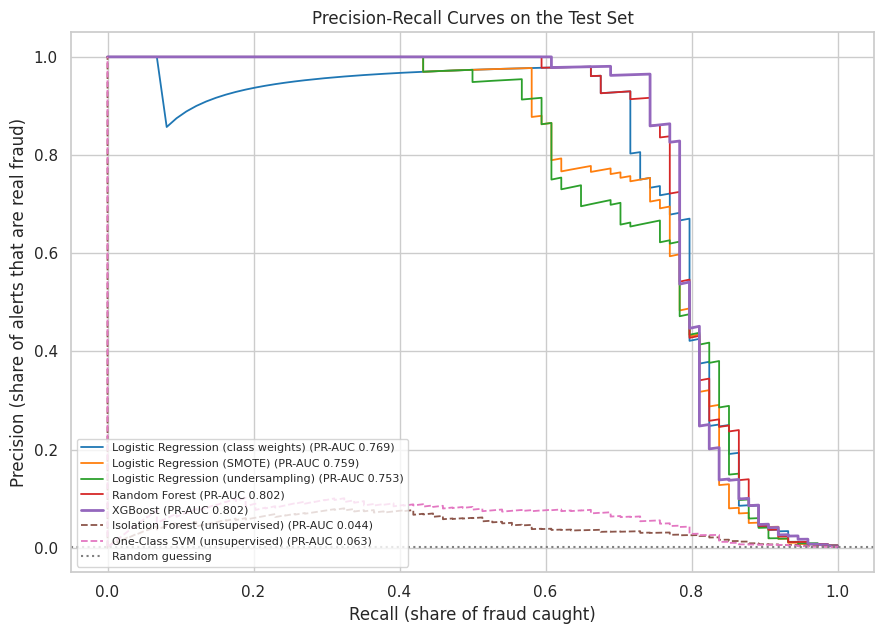

In [15]:
# Precision-recall curves: each point is one possible alert threshold
fig, ax = plt.subplots(figsize=(9, 6.5))
palette = dict(zip(test_scores.keys(), sns.color_palette("tab10", len(test_scores))))
for name, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    style = "--" if "unsupervised" in name else "-"
    ax.plot(recall, precision, style, color=palette[name], lw=2 if name == "XGBoost" else 1.3,
            label=f"{name} (PR-AUC {average_precision_score(y_test, scores):.3f})")
ax.axhline(y_test.mean(), color="grey", ls=":", label="Random guessing")
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision (share of alerts that are real fraud)")
ax.set_title("Precision-Recall Curves on the Test Set")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/pr_curves.png", bbox_inches="tight")
plt.show()

**How to read the chart:** each curve shows the trade-off for one model as its alert threshold changes. Moving right means catching more fraud; moving down means more false alarms. Curves closer to the top-right corner are better.

**What I found:** XGBoost and Random Forest stay above about 85% precision until they've caught roughly three-quarters of the fraud. After that, every model's precision drops steeply: the remaining frauds look too similar to legitimate transactions to separate cleanly. The anomaly detectors (dashed lines) stay near the bottom throughout.

## 8. Interpreting the Best Model

**Why this step:** XGBoost has the best cross-validation PR-AUC (0.778), so it is my final model. Random Forest is essentially tied on the test set (both 0.802), but XGBoost is preferred because:
- it scored slightly higher in cross-validation, which is what I select on;
- it has the best precision and F1 at the default threshold (0.902 and 0.815);
- it trained about six times faster in the grid search (92 s vs 574 s), which matters for retraining as fraud patterns change.

A model a business relies on should also be understandable, so here I look at which features drive its decisions.

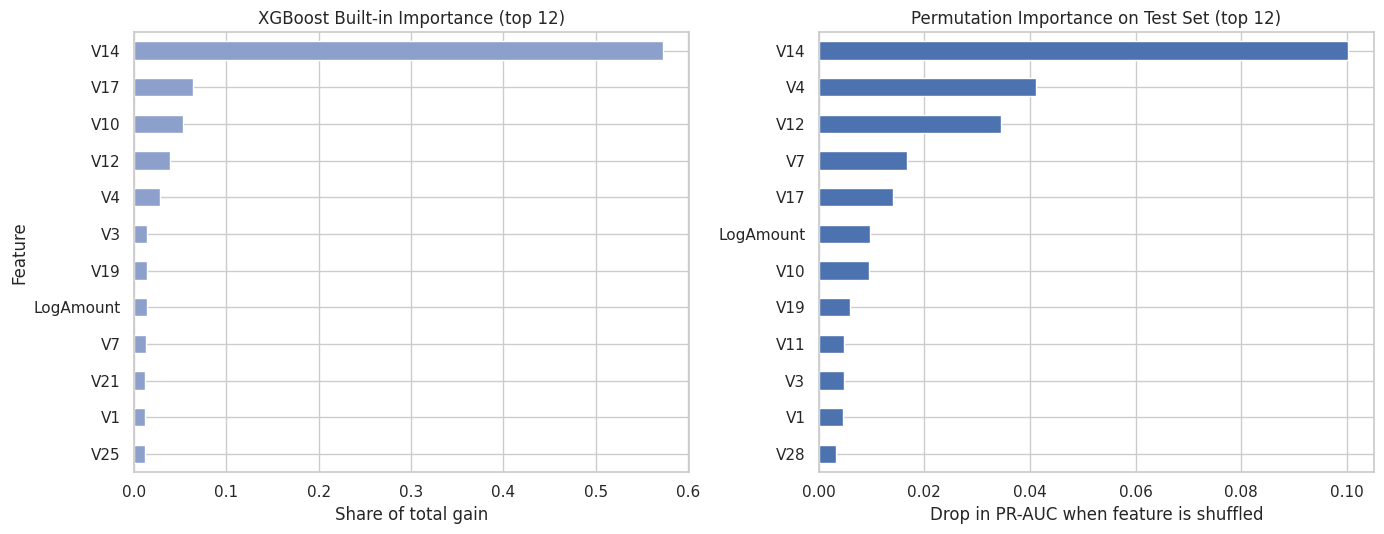

,Permutation rank,Drop in PR-AUC
LogAmount,6,0.0097
Hour,22,0.0010
IsNight,24,0.0000
IsMicroAmount,24,0.0000


In [16]:
# Two views of which features XGBoost relies on:
#  - Built-in importance (gain): how much each feature improved the trees' splits during training.
#  - Permutation importance: how much test PR-AUC drops when a feature's values are shuffled.
#    This is measured on unseen data, so it is the more trustworthy of the two.
final_model = best_models["XGBoost"]

gain = pd.Series(final_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
perm = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
gain.head(12).sort_values().plot.barh(ax=axes[0], color="#8DA0CB")
axes[0].set_title("XGBoost Built-in Importance (top 12)")
axes[0].set_xlabel("Share of total gain")
axes[0].set_ylabel("Feature")

perm_imp.head(12).sort_values().plot.barh(ax=axes[1], color="#4C72B0")
axes[1].set_title("Permutation Importance on Test Set (top 12)")
axes[1].set_xlabel("Drop in PR-AUC when feature is shuffled")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/feature_importance.png", bbox_inches="tight")
plt.show()

# Where do the engineered features rank?
engineered = ["LogAmount", "Hour", "IsNight", "IsMicroAmount"]
pd.DataFrame({"Permutation rank": perm_imp.rank(ascending=False).astype(int)[engineered],
              "Drop in PR-AUC": perm_imp[engineered].round(4)}).sort_values("Permutation rank")

**What I found:**
- **V14 dominates.** It accounts for over half of XGBoost's built-in importance, and shuffling it causes the biggest drop in test PR-AUC (about 0.10). V4, V12, V17 and V10 follow. These match the features notebook 1 flagged as most different between fraud and legitimate transactions, which suggests the model learned genuine patterns rather than noise.
- **V4 matters more than its simple correlation suggested.** It ranks second in permutation importance, likely because it is useful in combination with other features, something a tree model can exploit and a simple correlation cannot show.
- **Of my engineered features, only `LogAmount` adds measurable value** (rank 6 of 32). `Hour`, `IsNight` and `IsMicroAmount` contribute almost nothing on top of the V-features. Notebook 1 showed that night-time and micro-amount transactions are about 4 times riskier, but the anonymized features apparently already capture that information. The patterns are still useful for explaining fraud to a business audience, even if the model doesn't need them.
- **Limitation:** because the V-features are anonymized, I can say *which* features drive the model but not *what they mean* in business terms. A bank with access to the original features could explain individual decisions to customers and regulators.

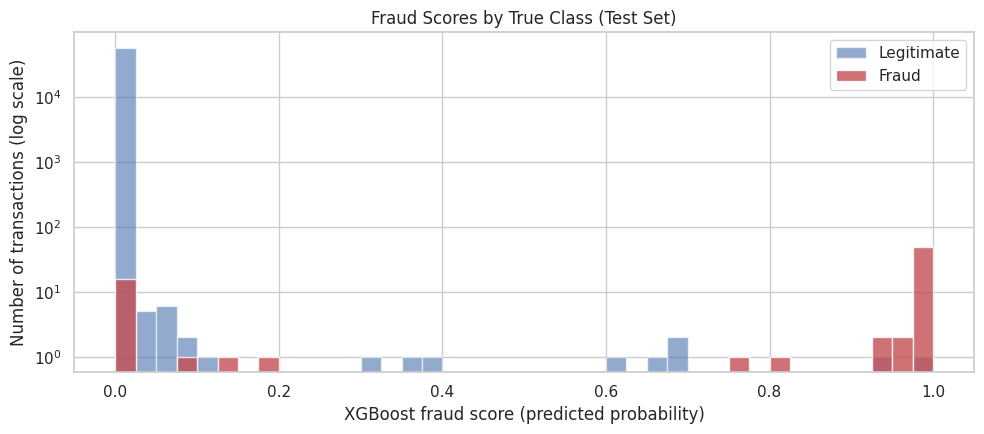

In [17]:
# How confidently does the model separate the two classes? Distribution of fraud scores on the test set.
xgb_test_scores = test_scores["XGBoost"]
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(0, 1, 41)
ax.hist(xgb_test_scores[y_test.values == 0], bins=bins, color="#4C72B0", alpha=0.6, label="Legitimate", log=True)
ax.hist(xgb_test_scores[y_test.values == 1], bins=bins, color="#C44E52", alpha=0.8, label="Fraud", log=True)
ax.set_xlabel("XGBoost fraud score (predicted probability)")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Fraud Scores by True Class (Test Set)")
ax.legend()
plt.tight_layout()
plt.show()

**What I found:** the model is very decisive. Almost all legitimate transactions score close to 0, and most frauds score close to 1, with very few transactions in between. (On the validation data, 99.6% of transactions score below 0.01 and only 0.05% fall between 0.1 and 0.9.) The practical consequence is that moving the threshold anywhere in the middle range changes very little, which the cost analysis in Section 9 confirms.

## 9. Choosing the Alert Threshold by Business Cost

**Why this step:** the model outputs a fraud score between 0 and 1. Someone must decide the cut-off above which a transaction is flagged for review. The default of 0.5 is arbitrary. Instead, I choose the threshold that minimizes the **total business cost**:

> **Total cost = losses from fraud that was missed + cost of reviewing every alert**

**Assumptions** (stated clearly because they drive the result):
- A **missed fraud** costs its full transaction amount, which the bank or merchant absorbs.
- **Every alert** costs **€5**: a few minutes of an analyst's time plus the inconvenience to the customer. This is an estimate, so I also test €1 to €25.
- A caught fraud is fully prevented.

**Avoiding test-set leakage:** I choose the threshold using **out-of-fold** predictions on the training data. Each validation block is scored by a model trained only on earlier data, exactly as in cross-validation. The test set is only used afterwards, to see what the chosen threshold would have achieved.

In [18]:
# Step 1: get "out-of-fold" fraud scores for the training data using the same time-aware folds.
# Each validation block is scored by a model trained only on earlier data, so these scores are
# honest, and they let me choose a threshold WITHOUT looking at the test set.
best_xgb_params = search_xgb.best_params_
oof_scores, oof_labels, oof_amounts = [], [], []
for tr_idx, val_idx in cv.split(X_train):
    fold_model = XGBClassifier(n_estimators=300, tree_method="hist", eval_metric="aucpr",
                               random_state=RANDOM_STATE, n_jobs=N_JOBS, **best_xgb_params)
    fold_model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    oof_scores.append(fold_model.predict_proba(X_train.iloc[val_idx])[:, 1])
    oof_labels.append(y_train.iloc[val_idx].values)
    oof_amounts.append(train["Amount"].iloc[val_idx].values)
oof_scores, oof_labels, oof_amounts = map(np.concatenate, (oof_scores, oof_labels, oof_amounts))
print(f"Validation transactions scored: {len(oof_scores):,} ({oof_labels.sum()} fraud)")

Validation transactions scored: 170,235 (242 fraud)


**What I found:** 170,235 validation transactions (242 frauds) now have honest fraud scores I can use to choose a threshold.

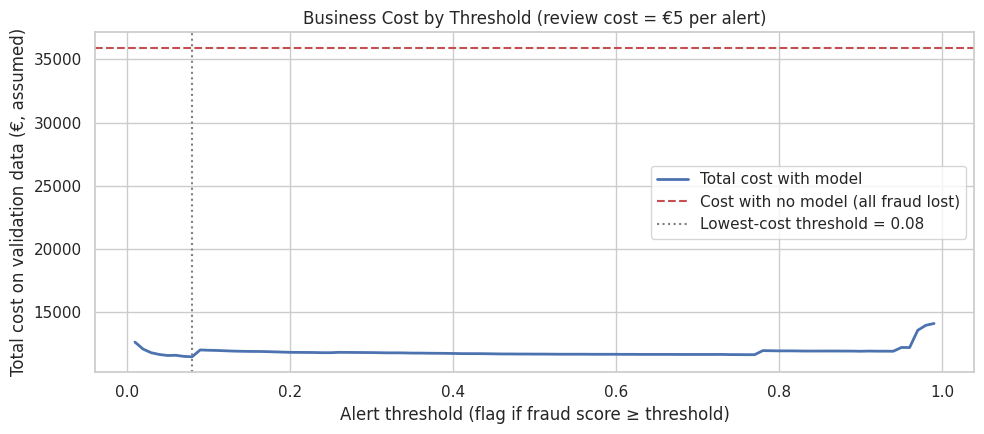

Lowest-cost threshold on validation data: 0.08


In [19]:
def business_cost(scores, labels, amounts, threshold, review_cost):
    """Total cost of running the model at a threshold.

    - Every alert costs `review_cost` (analyst time plus customer friction).
    - Every missed fraud costs its transaction amount (the loss is not prevented).
    """
    flagged = scores >= threshold
    missed_fraud_loss = amounts[(labels == 1) & ~flagged].sum()
    review_spend = flagged.sum() * review_cost
    return missed_fraud_loss + review_spend


REVIEW_COST = 5                                 # assumed cost per alert (see markdown for reasoning)
thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)

# Step 2: cost of every threshold on the validation data
val_costs = np.array([business_cost(oof_scores, oof_labels, oof_amounts, t, REVIEW_COST) for t in thresholds])
best_threshold = thresholds[val_costs.argmin()]

# Reference point: cost with no model at all (every fraud is lost, no reviews)
no_model_cost = oof_amounts[oof_labels == 1].sum()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thresholds, val_costs, color="#4C72B0", lw=2, label="Total cost with model")
ax.axhline(no_model_cost, color="#C44E52", ls="--", label="Cost with no model (all fraud lost)")
ax.axvline(best_threshold, color="grey", ls=":", label=f"Lowest-cost threshold = {best_threshold}")
ax.set_xlabel("Alert threshold (flag if fraud score ≥ threshold)")
ax.set_ylabel("Total cost on validation data (€, assumed)")
ax.set_title(f"Business Cost by Threshold (review cost = €{REVIEW_COST} per alert)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/cost_curve.png", bbox_inches="tight")
plt.show()

print(f"Lowest-cost threshold on validation data: {best_threshold}")

**How to read the chart:** the blue line is the total cost (missed-fraud losses plus review cost) at each threshold; lower is better. The red dashed line is the cost of having no fraud model at all.

**What I found:**
- **Using the model cuts total cost by about two-thirds** on the validation data: from about €35,900 with no model (every fraud lost) to about €11,500 at the best threshold.
- **The lowest-cost threshold is 0.08.** At this setting the model raised 295 alerts and caught 192 of 242 frauds on the validation data.
- **But the curve is almost flat.** Any threshold between 0.05 and 0.95 costs between about €11,500 and €12,200, within 6% of the best. The small steps in the line come from single large frauds: the jump just after 0.08 is one €571 fraud, and the jump near 0.77 is one €325 fraud. So the exact optimum depends on a handful of individual transactions and shouldn't be over-interpreted.

In [20]:
# Step 3: sensitivity check. The review cost is an assumption, so how much does the
# recommended threshold change if reviewing an alert is cheaper or more expensive?
sens_rows = []
for rc in [1, 2, 5, 10, 25]:
    costs = [business_cost(oof_scores, oof_labels, oof_amounts, t, rc) for t in thresholds]
    sens_rows.append({"Review cost per alert (€)": rc, "Lowest-cost threshold": thresholds[int(np.argmin(costs))]})
pd.DataFrame(sens_rows).set_index("Review cost per alert (€)")

,Lowest-cost threshold
Review cost per alert (€),
1,0.01
2,0.05
5,0.08
10,0.76
25,0.94


**What I found:** the "best" threshold swings from 0.01 to 0.94 as the review cost changes, but this looks more dramatic than it is. Because the cost curve is so flat, these thresholds all perform similarly. The swing is driven by a few borderline transactions. The real lesson: **for XGBoost, the threshold is not a sensitive decision.** Anything in the broad middle range works, so the business can choose based on review-team capacity. This is very different from Logistic Regression, whose scores are spread out and where the threshold changes the number of alerts by thousands (notebook 1, Section 8.3).

In [21]:
# Step 4: apply the chosen threshold to the untouched test set and translate into business terms.
def outcome(name, flagged, labels=y_test.values, amounts=amount_test, review_cost=REVIEW_COST):
    """Summarize what a flagging strategy would have meant on the test period."""
    caught = (flagged & (labels == 1))
    missed = (~flagged & (labels == 1))
    return {
        "Strategy": name,
        "Alerts": int(flagged.sum()),
        "Fraud caught": int(caught.sum()),
        "Fraud missed": int(missed.sum()),
        "False alarms": int((flagged & (labels == 0)).sum()),
        "Recall": caught.sum() / labels.sum(),
        "Precision": caught.sum() / flagged.sum() if flagged.sum() else 0,
        "Fraud € prevented": amounts[caught].sum(),
        "Fraud € lost": amounts[missed].sum(),
        "Total cost (€)": amounts[missed].sum() + flagged.sum() * review_cost,
    }

xgb_flags = xgb_test_scores >= best_threshold
strategies = pd.DataFrame([
    outcome("No fraud model", np.zeros(len(y_test), dtype=bool)),
    outcome("Simple rule: flag amounts ≥ €500", amount_test >= 500),
    outcome("Logistic Regression baseline (0.5)", test_scores["Logistic Regression (class weights)"] >= 0.5),
    outcome("XGBoost, default threshold (0.5)", xgb_test_scores >= 0.5),
    outcome(f"XGBoost, cost-based threshold ({best_threshold})", xgb_flags),
]).set_index("Strategy")
strategies.round({"Recall": 3, "Precision": 3, "Fraud € prevented": 0, "Fraud € lost": 0, "Total cost (€)": 0})

,Alerts,Fraud caught,Fraud missed,False alarms,Recall,Precision,Fraud € prevented,Fraud € lost,Total cost (€)
Strategy,,,,,,,,,
No fraud model,0,0,74,0,0.000,0.000,0.0,7728.0,7728.0
Simple rule: flag amounts ≥ €500,1613,4,70,1609,0.054,0.002,4232.0,3495.0,11560.0
Logistic Regression baseline (0.5),2472,69,5,2403,0.932,0.028,6379.0,1349.0,13709.0
"XGBoost, default threshold (0.5)",61,55,19,6,0.743,0.902,5050.0,2678.0,2983.0
"XGBoost, cost-based threshold (0.08)",68,57,17,11,0.770,0.838,5327.0,2401.0,2741.0


**What I found** (test period: 56,746 transactions, 74 frauds worth €7,728):

| Strategy | What happens |
|---|---|
| No fraud model | All €7,728 of fraud is lost. |
| Simple rule: flag amounts ≥ €500 | Reviews 1,613 transactions but catches only 4 frauds. Total cost (€11,560) is **higher than having no model**. Most fraud is small, so an amount rule misses it. |
| Logistic Regression baseline (0.5) | Catches 93% of fraud, but its 2,403 false alarms make it the **most expensive option** (€13,709). |
| XGBoost at 0.5 | Catches 55 frauds (74%) with only 6 false alarms. Cost €2,983. |
| **XGBoost at 0.08 (recommended)** | **Catches 57 frauds (77%) with only 11 false alarms. Cost €2,741, 65% lower than no model.** |

The two "intuitive" approaches, an amount rule and a model that catches nearly everything, both end up costing **more** than doing nothing, because of the review workload. The best approach catches slightly less fraud but is far more precise: 84% of its alerts are real fraud.

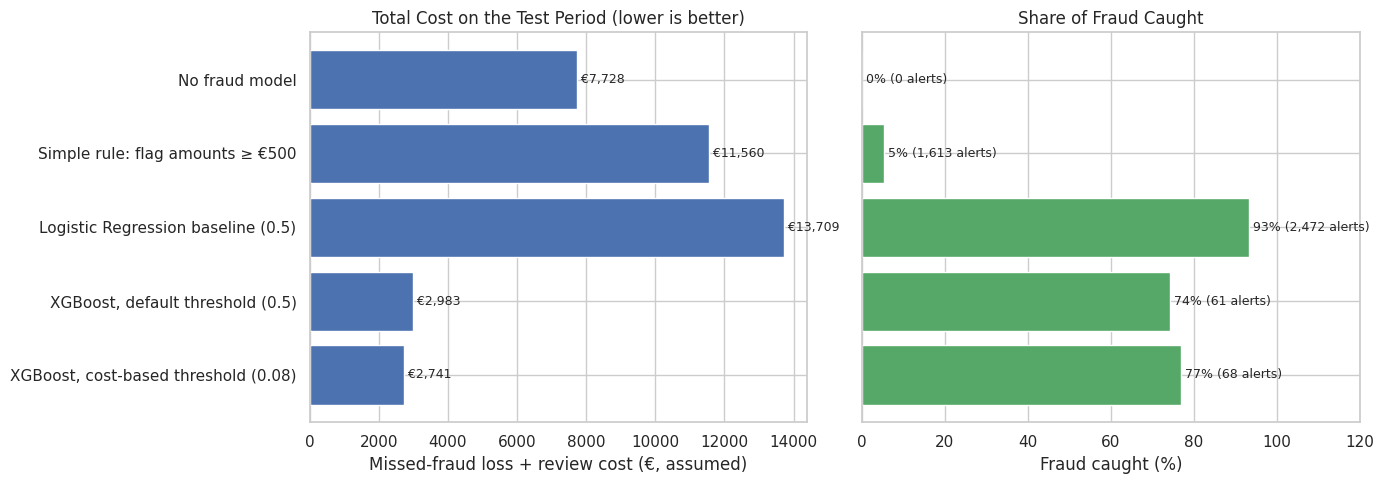

In [22]:
# Visual summary of the business comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = strategies.index[::-1]

axes[0].barh(order, strategies.loc[order, "Total cost (€)"], color="#4C72B0")
axes[0].set_title("Total Cost on the Test Period (lower is better)")
axes[0].set_xlabel("Missed-fraud loss + review cost (€, assumed)")
for i, v in enumerate(strategies.loc[order, "Total cost (€)"]):
    axes[0].text(v, i, f" €{v:,.0f}", va="center", fontsize=9)

axes[1].barh(order, strategies.loc[order, "Recall"] * 100, color="#55A868")
axes[1].set_title("Share of Fraud Caught")
axes[1].set_xlabel("Fraud caught (%)")
axes[1].set_yticklabels([])
for i, (r, a) in enumerate(zip(strategies.loc[order, "Recall"], strategies.loc[order, "Alerts"])):
    axes[1].text(r * 100, i, f" {r:.0%} ({a:,} alerts)", va="center", fontsize=9)
axes[1].set_xlim(0, 120)
plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/business_comparison.png", bbox_inches="tight")
plt.show()

**How to read the chart:** the left panel shows total cost (shorter is better); the right panel shows the share of fraud caught and how many alerts it took.

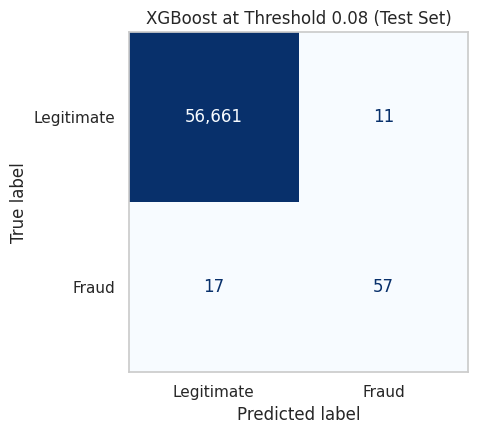

In [23]:
# Confusion matrix for the recommended setting
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, xgb_flags.astype(int)),
                       display_labels=["Legitimate", "Fraud"]).plot(cmap="Blues", values_format=",", colorbar=False, ax=ax)
ax.set_title(f"XGBoost at Threshold {best_threshold} (Test Set)")
ax.grid(False)
plt.tight_layout()
plt.savefig(f"{IMAGE_DIR}/final_confusion_matrix.png", bbox_inches="tight")
plt.show()

**What I found:** at the recommended threshold, the model lets 56,661 of 56,672 legitimate transactions through untouched, flags only 11 genuine customers, catches 57 frauds and misses 17. In practical terms, a review team would look at about 68 alerts over this period, and about 5 out of every 6 would be real fraud.

## 10. Can Anomaly Detection Act as a Safety Net?

**Why this step:** my proposal suggested the unsupervised models might work best as a backup, catching fraud the main model misses. Section 7 showed they are weak on their own, but they might still be useful if they catch *different* fraud. This cell tests that directly.

In [24]:
# Of the frauds XGBoost misses at the recommended threshold, how many would Isolation Forest
# rank among its most unusual transactions? (Top 1% of anomaly scores in the test period.)
iso_cutoff = np.quantile(iso_scores, 0.99)
missed_mask = (~xgb_flags) & (y_test.values == 1)
caught_by_iso = missed_mask & (iso_scores >= iso_cutoff)

print(f"Frauds missed by XGBoost: {missed_mask.sum()}")
print(f"...of which Isolation Forest ranks in its top 1%: {caught_by_iso.sum()}")
print(f"Cost of that safety net: {int((iso_scores >= iso_cutoff).sum()):,} extra transactions to review "
      f"(top 1% of {len(iso_scores):,})")

Frauds missed by XGBoost: 17
...of which Isolation Forest ranks in its top 1%: 2
Cost of that safety net: 568 extra transactions to review (top 1% of 56,746)


**What I found:** of the 17 frauds XGBoost misses, Isolation Forest would catch only 2, and it would need 568 extra reviews to do so: roughly 280 reviews per extra fraud caught. At €5 per review, that's about €2,840 of review cost to prevent two frauds. **Anomaly detection is not a worthwhile safety net on this data.** The frauds XGBoost misses aren't unusual-looking; they closely resemble legitimate transactions, which is why every method struggles with them.

## 11. Findings and Recommendations

### Answer to the research question
**Yes.** A tuned XGBoost model catches **77% of fraud** on unseen data while keeping false alarms very low: **only 11 genuine customers were flagged out of 56,672**, and 84% of alerts were real fraud. Compared with having no fraud model, it cuts the combined cost of fraud losses and alert reviews by **65%** on the test period (from €7,728 to €2,741).

### Key findings
1. **Tree-based models are the best approach.** XGBoost and Random Forest (test PR-AUC 0.802) outperform every Logistic Regression variant (best 0.769). XGBoost is recommended because it scored best in cross-validation, has the highest precision, and trains about six times faster than Random Forest.
2. **The simplest imbalance fix works best.** Telling the model that fraud matters more (class weighting) did as well as or better than generating synthetic fraud (SMOTE) or discarding legitimate data (undersampling).
3. **Catching more fraud is not automatically better.** A model tuned to catch 93% of fraud and a simple "flag large amounts" rule both cost **more than doing nothing**, because of the review workload their false alarms create.
4. **For XGBoost, the exact alert threshold matters little.** Its scores are very decisive, so any threshold in a broad middle range gives similar results. The business can set it based on how many alerts the review team can handle.
5. **Anomaly detection is not useful here.** Unsupervised models scored a PR-AUC below 0.07, and as a backup they would need about 280 extra reviews for every additional fraud caught.
6. **About a quarter of fraud remains hard to catch.** These frauds look very similar to legitimate transactions in every feature available.

### Recommendations (for a fraud operations audience)
- **Use a gradient-boosting model (XGBoost) to score every transaction,** rather than amount-based rules.
- **Set the alert threshold based on review capacity, not on a default.** In this data, a threshold between roughly 0.05 and 0.8 gives similar total cost; 0.08 was marginally the best.
- **Don't chase maximum fraud capture.** Each extra fraud caught beyond about 75–80% costs a disproportionate number of false alarms and unhappy customers.
- **Retrain regularly.** Fraud levels varied noticeably across the two days of data. XGBoost's fast training and stable performance across settings make frequent retraining practical.
- **Treat micro-charges (≤ €1) and night-time activity as warning signs** in manual reviews and customer communications. They are about 4 times riskier than average, even though the model doesn't need them as separate inputs.

### Limitations
- The data covers only **two days** in 2013 and **74 test frauds**, so results such as "77% of fraud caught" could vary by several percentage points on other periods.
- The **€5 review cost** is an assumption, and amounts are assumed to be in euros.
- The anonymized features prevent explaining *why* a specific transaction was flagged, which a real bank would need for customers and regulators.

### Next steps
1. **Validate on a longer time period** (weeks or months of data) to confirm performance holds as fraud patterns change.
2. **Replace the assumed review cost with real figures** from a fraud operations team, including the cost of customer churn from false declines.
3. **Add customer-level features** unavailable here, such as how a transaction compares with that cardholder's usual spending, location and merchant history. These typically help with the hard-to-catch frauds that look normal in isolation.
4. **Add explanation tools (for example, SHAP values)** on the original, non-anonymized features so each alert comes with a reason analysts can act on.
5. **Monitor the model in production** and track precision and recall weekly, retraining when they drift.